In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv("/content/bank-additional-full-1 (1).csv")

In [ ]:
df

,"age;""job"";""marital"";""education"";""default"";""housing"";""loan"";""contact"";""month"";""day_of_week"";""duration"";""campaign"";""pdays"";""previous"";""poutcome"";""emp.var.rate"";""cons.price.idx"";""cons.conf.idx"";""euribor3m"";""nr.employed"";""y"""
0,"56;""housemaid"";""married"";""basic.4y"";""no"";""no"";..."
1,"57;""services"";""married"";""high.school"";""unknown..."
2,"37;""services"";""married"";""high.school"";""no"";""ye..."
3,"40;""admin."";""married"";""basic.6y"";""no"";""no"";""no..."
4,"56;""services"";""married"";""high.school"";""no"";""no..."
...,...
41194,"74;""retired"";""married"";""professional.course"";""..."
41195,"74;NA;""married"";""professional.course"";""no"";""ye..."
41196,"74;""retired"";""married"";NA;""no"";""yes"";""no"";""cel..."
41197,NA;NA;NA;NA;NA;NA;NA;NA;NA;NA;NA;NA;NA;NA;NA;N...


The above has only two columns. This dataset is separated by semicolon, which is one the csv standard separator. Hence, we give the below format

In [ ]:
df=pd.read_csv("/content/bank-additional-full-1 (1).csv",sep=";")
#specifying the separator in the dataset

In [ ]:
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56.0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57.0,services,married,high.school,unknown,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37.0,services,married,high.school,no,yes,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40.0,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56.0,services,married,high.school,no,no,yes,telephone,may,mon,...,1.0,999.0,0.0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41194,74.0,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,3.0,999.0,1.0,failure,-1.1,94.767,-50.8,1.028,4963.6,no
41195,74.0,NaN,married,professional.course,no,yes,no,cellular,nov,fri,...,3.0,999.0,1.0,failure,-1.1,94.767,-50.8,1.028,4963.6,no
41196,74.0,retired,married,NaN,no,yes,no,cellular,nov,fri,...,3.0,999.0,1.0,failure,-1.1,94.767,-50.8,1.028,4963.6,no
41197,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**1- Age-** Customer's age

**2- Job-** Job of customer

**3- Marital-** Marital status - i.e - married/unmarried..

**4- education-** Education level

**5- default-** Has the person failed to repay a loan before? , i.e- Bad credit history or not
(default is the failure to fulfill the legal obligations or repayment terms of a loan)

**6- housing-** Does the person have a home loan?

**7- loan-** Does the person have any personal loan?

**8- contact-** How the bank contacted the person
i.e- cellular, telephone

**9- month-** Month when contact happened

**10- day_of_week-** Day of the week

**11- duration-** Duration of the call (in seconds)

**12- campaign-** Number of contacts made to this person in this campaign

**13- pdays-** Days since the person was last contacted

**14- previous-** Number of contacts before this campaign

**15- poutcome-** Result of previous campaign

**16- emp.var.rate (employment variation rate)-** Economic indicator

**17- cons.price.idx (consumer price index)-** Measures inflation

**18- cons.conf.idx (consumer confidence index)-** How confident people feel about economy

**19- euribor3m-** Interest rate (Euro interbank rate - 3 months)

**20- nr.employed-** Number of employees in the economy

**21- y (Target variable)-** Final result



**Target Column -> y (Predict whether a customer will subscribe to a term deposit or not)**

yes or no -> categorical output => logistic regression

In [ ]:
#check info on dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41199 entries, 0 to 41198
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41195 non-null  float64
 1   job             41194 non-null  object 
 2   marital         41194 non-null  object 
 3   education       41194 non-null  object 
 4   default         41195 non-null  object 
 5   housing         41196 non-null  object 
 6   loan            41195 non-null  object 
 7   contact         41195 non-null  object 
 8   month           41196 non-null  object 
 9   day_of_week     41196 non-null  object 
 10  duration        41196 non-null  float64
 11  campaign        41196 non-null  float64
 12  pdays           41196 non-null  float64
 13  previous        41196 non-null  float64
 14  poutcome        41194 non-null  object 
 15  emp.var.rate    41196 non-null  float64
 16  cons.price.idx  41195 non-null  float64
 17  cons.conf.idx   41196 non-null 

In [ ]:
df.duplicated().sum()

np.int64(15)

In [ ]:
df.shape

(41199, 21)

In [ ]:
df.isna().sum()

,0
age,4
job,5
marital,5
education,5
default,4
housing,3
loan,4
contact,4
month,3
day_of_week,3


In [ ]:
df.isna().sum().sum()

np.int64(76)

In [ ]:
#handle the duplicates and nulls
#they can be dropped -> 15+76 -> very less in number when compared to 41k rows so can be dropped

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(41184, 21)

In [ ]:
df.dropna(inplace=True)

In [ ]:
df.shape

(41177, 21)

In [ ]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000,41177.000000
mean,40.025111,258.315346,2.567890,962.465697,0.173033,0.081893,93.575749,-40.503113,3.621230,5167.029929
std,10.423948,259.302190,2.770286,186.934918,0.494975,1.570874,0.578862,4.628082,1.734463,72.257442
min,17.000000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.000000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.000000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.000000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.000000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


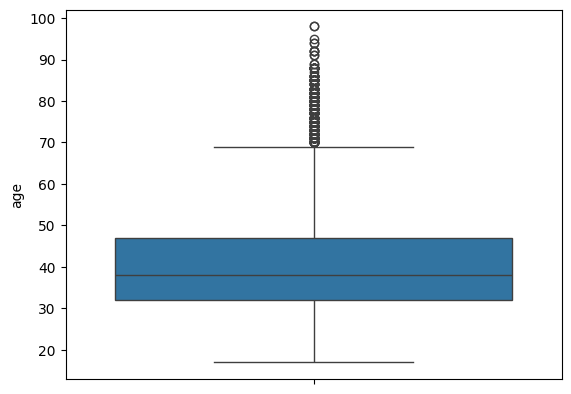

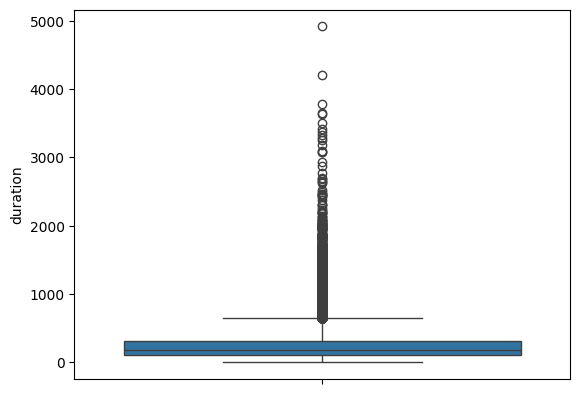

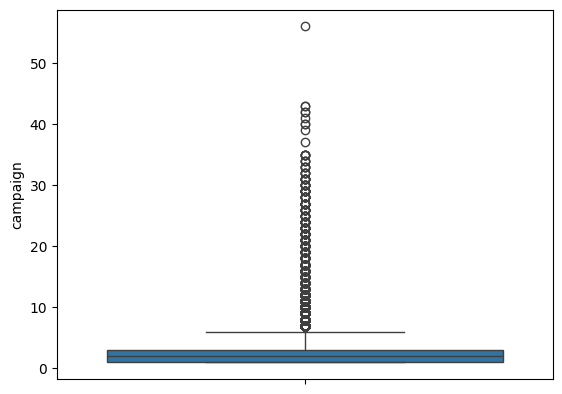

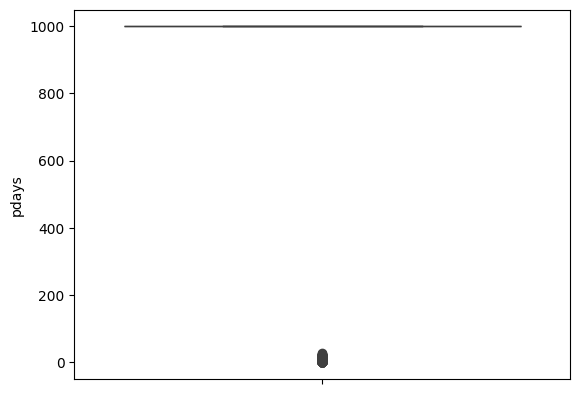

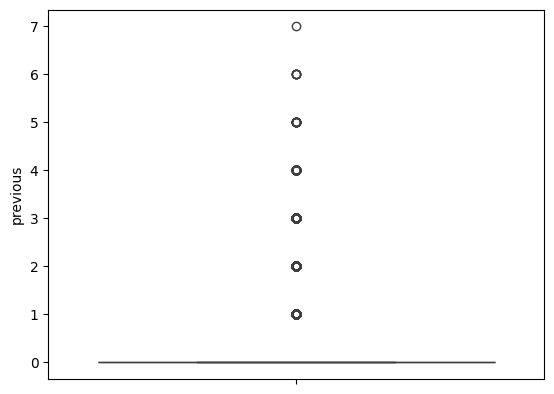

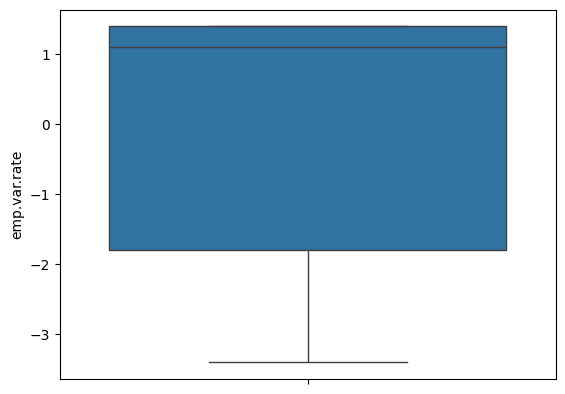

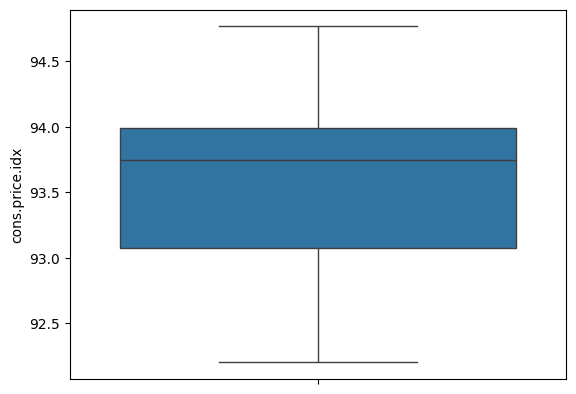

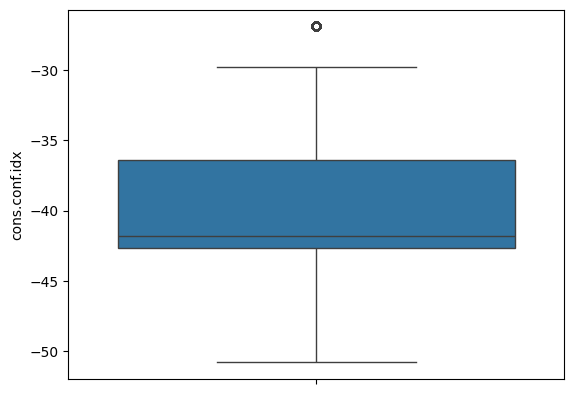

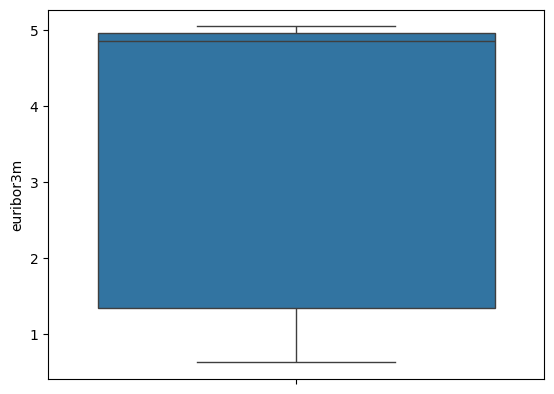

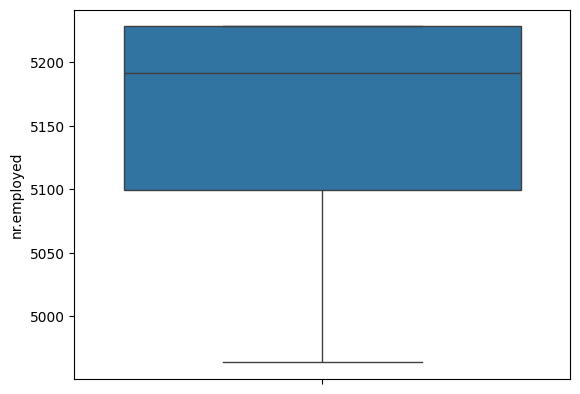

In [ ]:
for col in df.columns:
  if df[col].dtype != 'object':
    sns.boxplot(df[col])
    plt.show()

with the reference of the above boxplot we can observe that some columns have outliers-

1- age - there are outliers

2- duration - there are outliers

3- campaign - there are outliers

4- pdays - there are no outliers - no box

5- previous - there are no outliers - no box

6- emp.var.rate - there are no outliers

7- cons.price.idx - there are no outliers

8- cons.conf.idx - there are outliers

9- nr.employeed - there are no outliers

#Outliers need to be removed as linear and logistic models are highly sensitive to them

Remove via IQR: When data should be symmetric/compact, and extreme points are likely data entry errors or completely irrelevant to the target goal(age)

Leave As-Is: When data is naturally heavily skewed (like duration, income, or web traffic) and the extreme values contain the exact behavioral insights you are trying to predict.
(duration)

 Context and business logic always override generic statistical rules.

In [ ]:
#listing all columns where we need to handle outliers
out_cols=['age','campaign','cons.conf.idx']
for col in out_cols:
  q1=df[col].quantile(0.25) #calculating q1
  q3=df[col].quantile(0.75) #calculating q3
  iqr=q3-q1 #calculating inter quartile range
  lb=q1-1.5*iqr
  ub=q3+1.5*iqr
  df=df[(df[col]>=lb)&(df[col]<=ub)]

#handled all outliers

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 37924 entries, 0 to 41186
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             37924 non-null  float64
 1   job             37924 non-null  object 
 2   marital         37924 non-null  object 
 3   education       37924 non-null  object 
 4   default         37924 non-null  object 
 5   housing         37924 non-null  object 
 6   loan            37924 non-null  object 
 7   contact         37924 non-null  object 
 8   month           37924 non-null  object 
 9   day_of_week     37924 non-null  object 
 10  duration        37924 non-null  float64
 11  campaign        37924 non-null  float64
 12  pdays           37924 non-null  float64
 13  previous        37924 non-null  float64
 14  poutcome        37924 non-null  object 
 15  emp.var.rate    37924 non-null  float64
 16  cons.price.idx  37924 non-null  float64
 17  cons.conf.idx   37924 non-null  floa

In [ ]:
# convert the value of target column or y from yes/no to 0,1(encoding for the \
#machine to be able to work on it)

In [ ]:
# there are lots of object data type columns -> encode them too

In [ ]:
#first, we handle the y column
df['y']=np.where(df['y']=='yes',1,0)
#syntax: np.where(col and filter condition, value filled for trye, value fill for false)
# the where condition is used to fill with the first number, wherever the condition satisfies
# works only with a numpy array

In [ ]:
df['y'].unique()
# now all 0s and 1s

array([0, 1])

In [ ]:
# now we do encoding for object data

In [ ]:
# giving relevant, representative numbers to all object/categorical/strings
# to convert into numbers for ml models

**Encoding?**

In machine learning models works only with numeric data. So we need to convert text data to numbers . The process of converting text to numbers is known as encoding

**Label Encoding-** used when we have 2 categories or data is in order

- **how it works?**

-1- find unique values

-2- sort them alphabetically

-3- assign them numbers starting from 0

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
le=LabelEncoder()

In [ ]:
#for col in df.columns:
 # if df[col].dtype == 'object':
    # df[col]=le.fit_transform(df[col])

    #code for just encoding -> commented out because the next one wont run as
    # all will be converted into numerical by the time it runs

In [ ]:
#check the types
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 37924 entries, 0 to 41186
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             37924 non-null  float64
 1   job             37924 non-null  object 
 2   marital         37924 non-null  object 
 3   education       37924 non-null  object 
 4   default         37924 non-null  object 
 5   housing         37924 non-null  object 
 6   loan            37924 non-null  object 
 7   contact         37924 non-null  object 
 8   month           37924 non-null  object 
 9   day_of_week     37924 non-null  object 
 10  duration        37924 non-null  float64
 11  campaign        37924 non-null  float64
 12  pdays           37924 non-null  float64
 13  previous        37924 non-null  float64
 14  poutcome        37924 non-null  object 
 15  emp.var.rate    37924 non-null  float64
 16  cons.price.idx  37924 non-null  float64
 17  cons.conf.idx   37924 non-null  floa

Ordinal Encoder gives numbers according to the rankings of the labels
EX: Student grades

In [ ]:
#if we wish to see what numbers are given to each of the categories: how encoding is done(mapping)
encoders={} #empty dictionary; columns:encoders
for col in df.columns:
  if df[col].dtype == 'object':
    le=LabelEncoder() #creating a fresh object for that column encoding
    df[col]=le.fit_transform(df[col])
    encoders[col]=le # storing the encoder for each column

In [ ]:
# to check mapping
encoders['job'].classes_
#.classes_ attribute gives back the array of all possible values in the job column
# in alphabetical order
#the array index of the values becomes the code given to the values/ categories

array(['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management',
       'retired', 'self-employed', 'services', 'student', 'technician',
       'unemployed', 'unknown'], dtype=object)

#Now we move on to the next part of preprocessing -> VIF and Feature selection

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 37924 entries, 0 to 41186
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             37924 non-null  float64
 1   job             37924 non-null  int64  
 2   marital         37924 non-null  int64  
 3   education       37924 non-null  int64  
 4   default         37924 non-null  int64  
 5   housing         37924 non-null  int64  
 6   loan            37924 non-null  int64  
 7   contact         37924 non-null  int64  
 8   month           37924 non-null  int64  
 9   day_of_week     37924 non-null  int64  
 10  duration        37924 non-null  float64
 11  campaign        37924 non-null  float64
 12  pdays           37924 non-null  float64
 13  previous        37924 non-null  float64
 14  poutcome        37924 non-null  int64  
 15  emp.var.rate    37924 non-null  float64
 16  cons.price.idx  37924 non-null  float64
 17  cons.conf.idx   37924 non-null  floa

In [ ]:
#first, check the corelation for the data
cor=df.corr()
cor
#displays a corelation matrix, each col vs each col

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
age,1.000000,-0.016738,-0.391394,-0.099169,0.191619,-0.003585,-0.005980,0.034663,-0.031999,-0.025962,...,0.010725,0.005727,-0.022616,0.017423,0.072782,0.038575,0.103126,0.084213,0.069324,-0.020355
job,-0.016738,1.000000,0.033651,0.141981,-0.029102,0.006311,-0.009225,-0.022038,-0.035467,-0.000863,...,-0.007528,-0.027037,0.019780,0.010740,-0.000822,-0.009795,0.048880,-0.001096,-0.012024,0.020196
marital,-0.391394,0.033651,1.000000,0.105932,-0.081780,0.011575,0.005208,-0.062190,-0.012088,0.006653,...,-0.011395,-0.049411,0.048776,0.005007,-0.098805,-0.062280,-0.033791,-0.107298,-0.105811,0.057249
education,-0.099169,0.141981,0.105932,1.000000,-0.192713,0.016057,0.004779,-0.110610,-0.084805,-0.019742,...,-0.001743,-0.058969,0.048082,0.020446,-0.058003,-0.087355,0.086050,-0.050438,-0.059640,0.069332
default,0.191619,-0.029102,-0.081780,-0.192713,1.000000,-0.016660,-0.003366,0.131986,-0.010778,-0.008155,...,0.025410,0.081829,-0.102139,0.021361,0.198645,0.159358,0.045545,0.190475,0.185942,-0.097662
housing,-0.003585,0.006311,0.011575,0.016057,-0.016660,1.000000,0.044530,-0.083288,-0.020734,-0.000104,...,-0.008816,-0.010835,0.023730,-0.012673,-0.060824,-0.081965,-0.034799,-0.058843,-0.045285,0.011813
loan,-0.005980,-0.009225,0.005208,0.004779,-0.003366,0.044530,1.000000,-0.006832,-0.003778,-0.008969,...,0.012684,0.000448,-0.000563,-0.002308,0.000465,-0.003380,-0.008154,-0.001057,0.001955,-0.003273
contact,0.034663,-0.022038,-0.062190,-0.110610,0.131986,-0.083288,-0.006832,1.000000,0.291766,-0.007397,...,0.041774,0.114671,-0.212920,0.123575,0.398727,0.600917,0.299898,0.402600,0.265127,-0.140091
month,-0.031999,-0.035467,-0.012088,-0.084805,-0.010778,-0.020734,-0.003778,0.291766,1.000000,0.035925,...,-0.035966,-0.035212,0.091449,-0.065034,-0.135480,0.034640,-0.039343,-0.079183,-0.182144,-0.023942
day_of_week,-0.025962,-0.000863,0.006653,-0.019742,-0.008155,-0.000104,-0.008969,-0.007397,0.035925,1.000000,...,-0.051951,-0.010135,-0.004726,0.019039,0.036633,0.008646,0.043768,0.042430,0.032001,0.015531


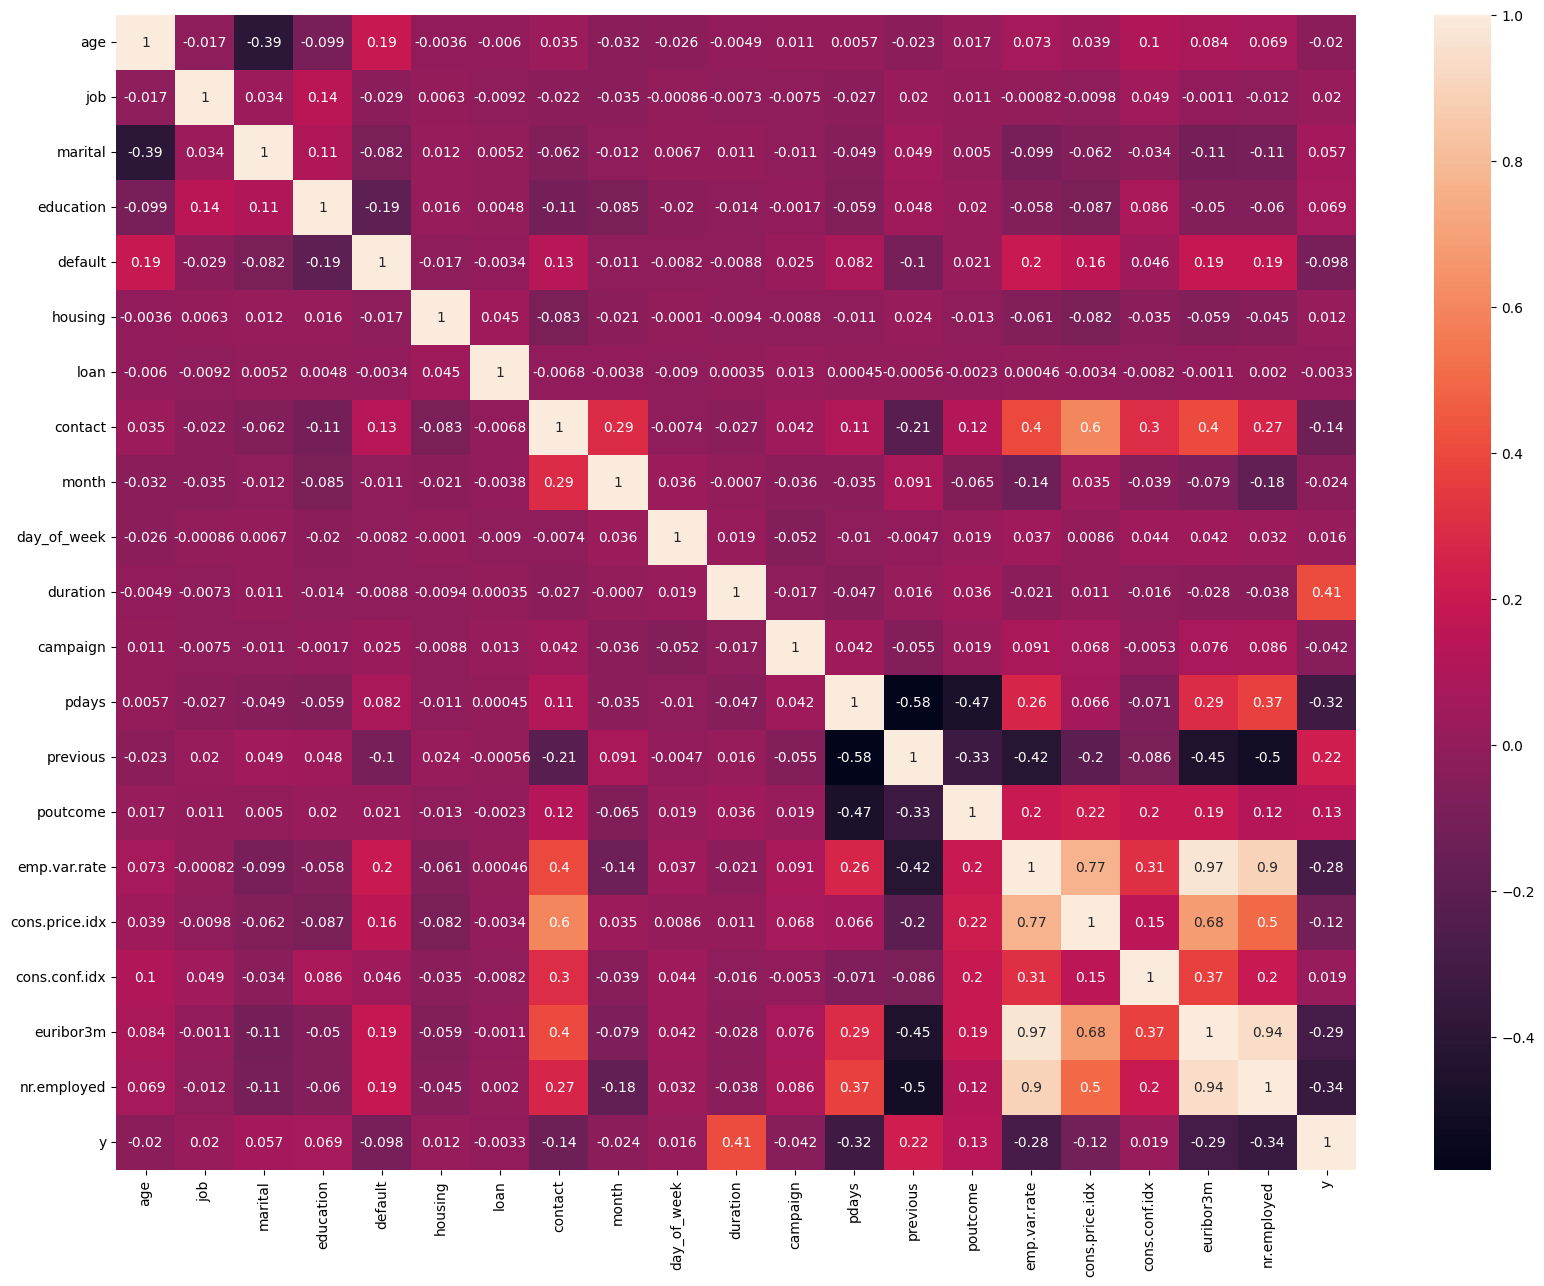

In [ ]:
# to visualize -> corelation heatmap
plt.figure(figsize=(20,15))
sns.heatmap(df.corr(),annot=True)
plt.show()

#VIF

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [ ]:
# create an empty list
col_list = []
for i in df.columns:
  if((df[i].dtype!='object') & (i!='y')):
    col_list.append(i)
#basically taking only those columns that have numerical data and excluding the target colummn
# which is the entire dataset now
#selects the chunk of data that has these columns (i.e. whole set exclu y)

X = df[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_Score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]


In [ ]:
vif_data

,Column_name,VIF_Score
0,age,22.094009
1,job,2.103833
2,marital,5.696153
3,education,4.552022
4,default,1.411500
5,housing,2.209099
6,loan,1.208310
7,contact,2.911689
8,month,6.628310
9,day_of_week,3.105219


In [ ]:
# VIF SCORE VALUE --- 1 ----(no multicolinarity)
# 1-5 --------------(low multicolinearity)
# 5 or gretear than 5 ----------------(high multicolinearity)

In [ ]:
#remove columns with high vif
df.drop('nr.employed',axis=1,inplace=True)

In [ ]:
col_list = []
for i in df.columns:
  if((df[i].dtype!='object') & (i!='y')):
    col_list.append(i)
X = df[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_Score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]
vif_data

,Column_name,VIF_Score
0,age,22.086433
1,job,2.103677
2,marital,5.695430
3,education,4.550236
4,default,1.408577
5,housing,2.208636
6,loan,1.208242
7,contact,2.429719
8,month,5.729878
9,day_of_week,3.104551


In [ ]:
df.drop('cons.price.idx',axis=1,inplace=True)

In [ ]:
col_list = []
for i in df.columns:
  if((df[i].dtype!='object') & (i!='y')):
    col_list.append(i)
X = df[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_Score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]
vif_data

,Column_name,VIF_Score
0,age,20.923074
1,job,2.097951
2,marital,5.545062
3,education,4.495580
4,default,1.408562
5,housing,2.207167
6,loan,1.207836
7,contact,2.331535
8,month,5.677704
9,day_of_week,3.087990


In [ ]:
df.drop('pdays',axis=1,inplace=True)

In [ ]:
col_list = []
for i in df.columns:
  if((df[i].dtype!='object') & (i!='y')):
    col_list.append(i)
X = df[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_Score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]
vif_data

,Column_name,VIF_Score
0,age,20.051552
1,job,2.094760
2,marital,5.425401
3,education,4.443527
4,default,1.408515
5,housing,2.203867
6,loan,1.207718
7,contact,2.261900
8,month,5.624066
9,day_of_week,3.075360


In [ ]:
df.drop('euribor3m',axis=1,inplace=True)

In [ ]:
col_list = []
for i in df.columns:
  if((df[i].dtype!='object') & (i!='y')):
    col_list.append(i)
X = df[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_Score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]
vif_data

,Column_name,VIF_Score
0,age,17.135159
1,job,2.088219
2,marital,5.228734
3,education,4.288757
4,default,1.408089
5,housing,2.195583
6,loan,1.207393
7,contact,2.252173
8,month,5.240122
9,day_of_week,3.035109


In [ ]:
df.drop('cons.conf.idx',axis=1,inplace=True)

In [ ]:
col_list = []
for i in df.columns:
  if((df[i].dtype!='object') & (i!='y')):
    col_list.append(i)
X = df[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_Score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]
vif_data

,Column_name,VIF_Score
0,age,10.785752
1,job,2.079422
2,marital,4.345803
3,education,4.190893
4,default,1.407227
5,housing,2.160176
6,loan,1.204344
7,contact,2.227388
8,month,4.845232
9,day_of_week,2.968324


In [ ]:
df.drop('age',axis=1,inplace=True)

In [ ]:
col_list = []
for i in df.columns:
  if((df[i].dtype!='object') & (i!='y')):
    col_list.append(i)
X = df[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_Score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]
vif_data

,Column_name,VIF_Score
0,job,2.055353
1,marital,4.331653
2,education,4.001365
3,default,1.320670
4,housing,2.107399
5,loan,1.201191
6,contact,2.225942
7,month,4.563485
8,day_of_week,2.875615
9,duration,1.966128


In [ ]:
df.drop('poutcome',axis=1,inplace=True)

In [ ]:
col_list = []
for i in df.columns:
  if((df[i].dtype!='object') & (i!='y')):
    col_list.append(i)
X = df[col_list]
vif_data = pd.DataFrame()
vif_data['Column_name'] = X.columns
vif_data['VIF_Score'] = [variance_inflation_factor(X.values,i) for i in range(len(X.columns))]
vif_data

,Column_name,VIF_Score
0,job,2.034334
1,marital,4.089345
2,education,3.755596
3,default,1.309502
4,housing,2.070982
5,loan,1.199049
6,contact,2.209531
7,month,4.423472
8,day_of_week,2.775780
9,duration,1.915100


In [ ]:
#All values < 5 => dataset is model ready

#Model Building

In [ ]:
X

,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,previous,emp.var.rate
0,3,1,0,0,0,0,1,6,1,261.0,1.0,0.0,1.1
1,7,1,3,1,0,0,1,6,1,149.0,1.0,0.0,1.1
2,7,1,3,0,2,0,1,6,1,226.0,1.0,0.0,1.1
3,0,1,1,0,0,0,1,6,1,151.0,1.0,0.0,1.1
4,7,1,3,0,0,2,1,6,1,307.0,1.0,0.0,1.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
41181,0,1,6,0,2,0,0,7,0,281.0,1.0,0.0,-1.1
41182,10,2,0,0,2,0,0,7,0,112.0,1.0,1.0,-1.1
41184,1,1,5,0,0,0,0,7,0,383.0,1.0,0.0,-1.1
41185,5,1,6,0,2,0,0,7,0,189.0,2.0,0.0,-1.1


In [ ]:
y=df['y']
y

,y
0,0
1,0
2,0
3,0
4,0
...,...
41181,1
41182,0
41184,0
41185,0


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
model=LogisticRegression()

In [ ]:
model.fit(x_train,y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [ ]:
y_pred=model.predict(x_test)

In [ ]:
y_pred

array([0, 0, 1, ..., 0, 0, 0])

In [ ]:
from sklearn.metrics import *

In [ ]:
#R square for linear cuz that method takes continuous values

In [ ]:
#accuracy score for logistic because we have only two possible discrete values

In [ ]:
accuracy_score(y_test,y_pred)*100

89.86156888595913